<a href="https://colab.research.google.com/github/mmalofeev/statistics/blob/main/confidence_intervals.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import numpy as np
from scipy import stats, optimize
import matplotlib.pyplot as plt

In [9]:
lam = 5

In [10]:
sizes = [5, 20, 50, 100, 500, 1000, 2000, 5000, 10000]

In [11]:
def exponential_pdf(x, lam):
  return 1 / lam * np.exp(-( 1 / lam * x))

In [12]:
# we will estimate the parameter using MLE
def negative_log_likelyhood(lam, sample, pdf):
  return -np.sum(np.log(pdf(sample, lam)))

We will get the estimator $\hat{\lambda}$ from MLE which is asymptotically Normal, so we can calculate the 95% confidence interval as $C_n = (\hat{\lambda} - 1.96\,\hat{se},\ \hat{\lambda} + 1.96\,\hat{se})$
To get the estimated standard error, we will use the Fisher information evaluated at the estimate:
$$\hat{se} = \sqrt{\frac{1}{nI(\hat{\lambda})}}$$
Where
$$I(\lambda) = -E_{\lambda}\left(\frac{\partial^2 \log f(x; \lambda)}{\partial \lambda^2}\right)$$
$$f(x; \lambda) = \lambda e^{-\lambda x}$$
$$\log f(x; \lambda) = \log\lambda - \lambda x$$
$$\frac{\partial^2 \log f(x; \lambda)}{\partial \lambda^2} = -\frac{1}{\lambda^2}$$
The second derivative $-\frac{1}{\lambda^2}$ does not depend on $x$, so its expectation just equals $-\frac{1}{\lambda^2}$.
Hence,
$$I(\lambda) = \frac{1}{\lambda^2}$$
Plugging in the estimate $\hat{\lambda}$:
$$\hat{se} = \sqrt{\frac{1}{nI(\hat{\lambda})}} = \frac{\hat{\lambda}}{\sqrt{n}}$$

In [ ]:
def mle_estimate(data):
  f = lambda lam : negative_log_likelyhood(lam, data, exponential_pdf)
  res = optimize.minimize_scalar(f, 1, bounds=(1e-6, 100), method="bounded")
  return res

In [ ]:
attempts = 1000

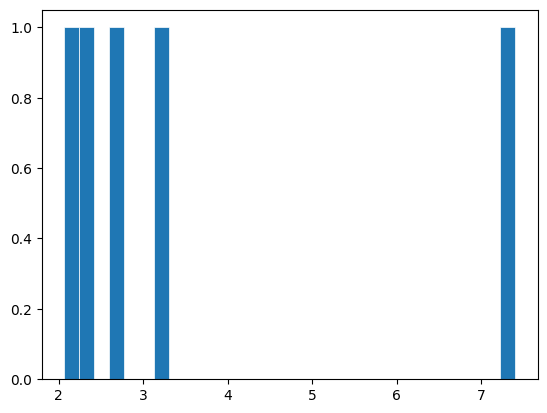

size = 5 the estimated parameter which is the result of MLE is 3.5181208893243276
estimated se is 1.5733514923182421
size = 5 86.0% of 95% confidence intervals contain the true value of lambda=5


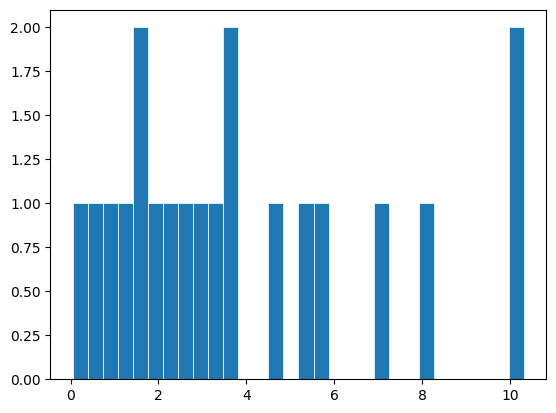

size = 20 the estimated parameter which is the result of MLE is 3.87073216755946
estimated se is 0.8655220249358058
size = 20 93.2% of 95% confidence intervals contain the true value of lambda=5


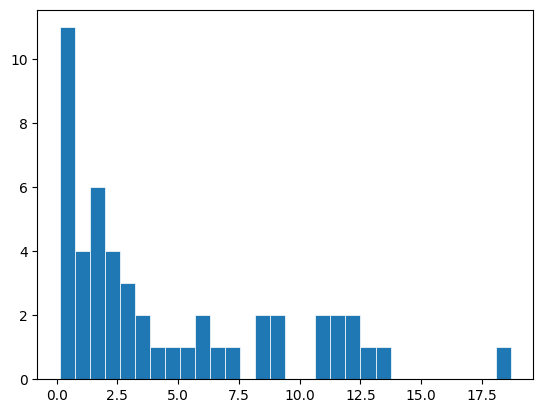

size = 50 the estimated parameter which is the result of MLE is 4.6573898893993535
estimated se is 0.6586543946847895
size = 50 94.0% of 95% confidence intervals contain the true value of lambda=5


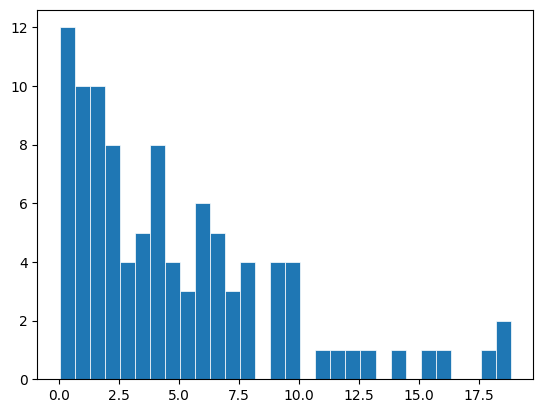

size = 100 the estimated parameter which is the result of MLE is 4.92388618079299
estimated se is 0.492388618079299
size = 100 94.3% of 95% confidence intervals contain the true value of lambda=5


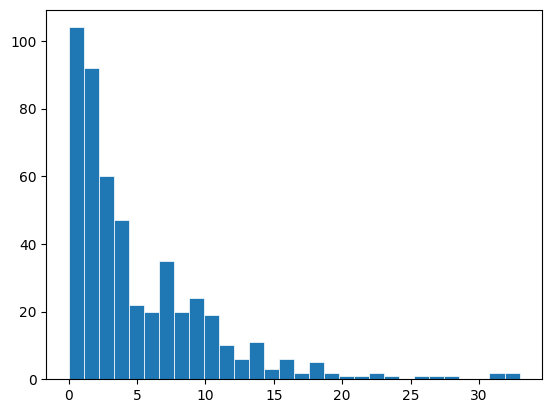

size = 500 the estimated parameter which is the result of MLE is 5.134825645473854
estimated se is 0.22963638391777544
size = 500 95.1% of 95% confidence intervals contain the true value of lambda=5


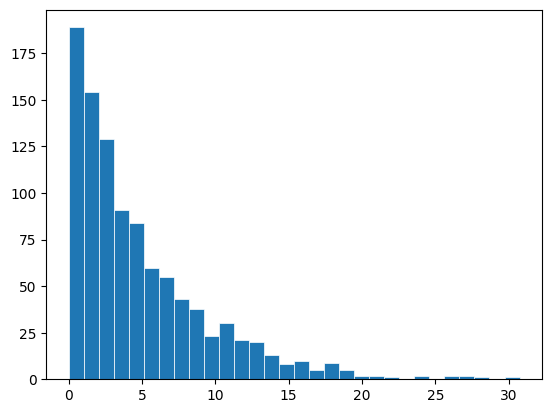

size = 1000 the estimated parameter which is the result of MLE is 4.900974301071423
estimated se is 0.15498241545337496
size = 1000 94.89999999999999% of 95% confidence intervals contain the true value of lambda=5


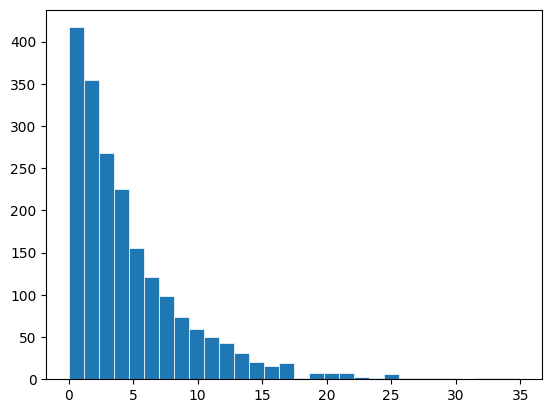

size = 2000 the estimated parameter which is the result of MLE is 4.781086493780003
estimated se is 0.10690834406398211
size = 2000 94.6% of 95% confidence intervals contain the true value of lambda=5


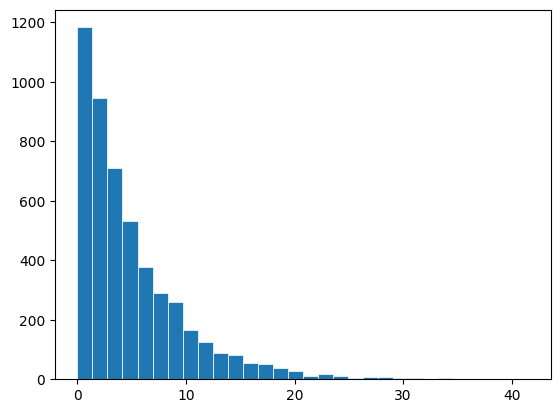

size = 5000 the estimated parameter which is the result of MLE is 4.996631148287111
estimated se is 0.07066303536083483
size = 5000 95.89999999999999% of 95% confidence intervals contain the true value of lambda=5


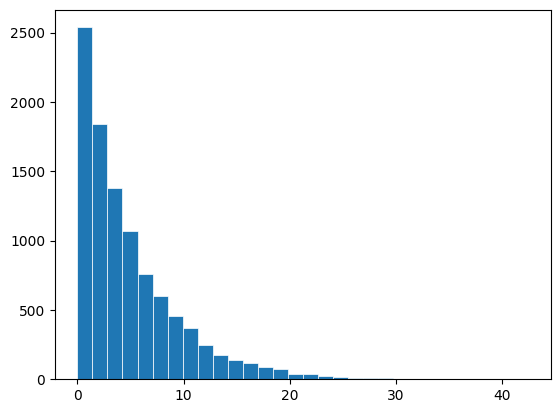

size = 10000 the estimated parameter which is the result of MLE is 4.934578171916125
estimated se is 0.04934578171916125
size = 10000 94.69999999999999% of 95% confidence intervals contain the true value of lambda=5


In [14]:
for size in sizes:
  interval_cnt_contains_true_val = 0
  for attempt in range(attempts):
    data = np.random.exponential(scale=lam, size=size)
    # draw a distribution
    if attempt == 0:
      fig, ax = plt.subplots()
      ax.hist(data, bins=30, linewidth=0.5, edgecolor="white")
      plt.show()
    res = mle_estimate(data)
    if attempt == 0:
      print(f"size = {size} the estimated parameter which is the result of MLE is {res.x}")
    estimated_se = res.x / np.sqrt(size)
    if attempt == 0:
      print(f"estimated se is {estimated_se}")
    c_n_left = res.x - 1.96 * estimated_se # 95% confidence interval
    c_n_right = res.x + 1.96 * estimated_se
    if c_n_left <= lam <= c_n_right:
      interval_cnt_contains_true_val += 1
  print(f"size = {size} {interval_cnt_contains_true_val / attempts * 100}% of 95% confidence intervals contain the true value of lambda={lam}")